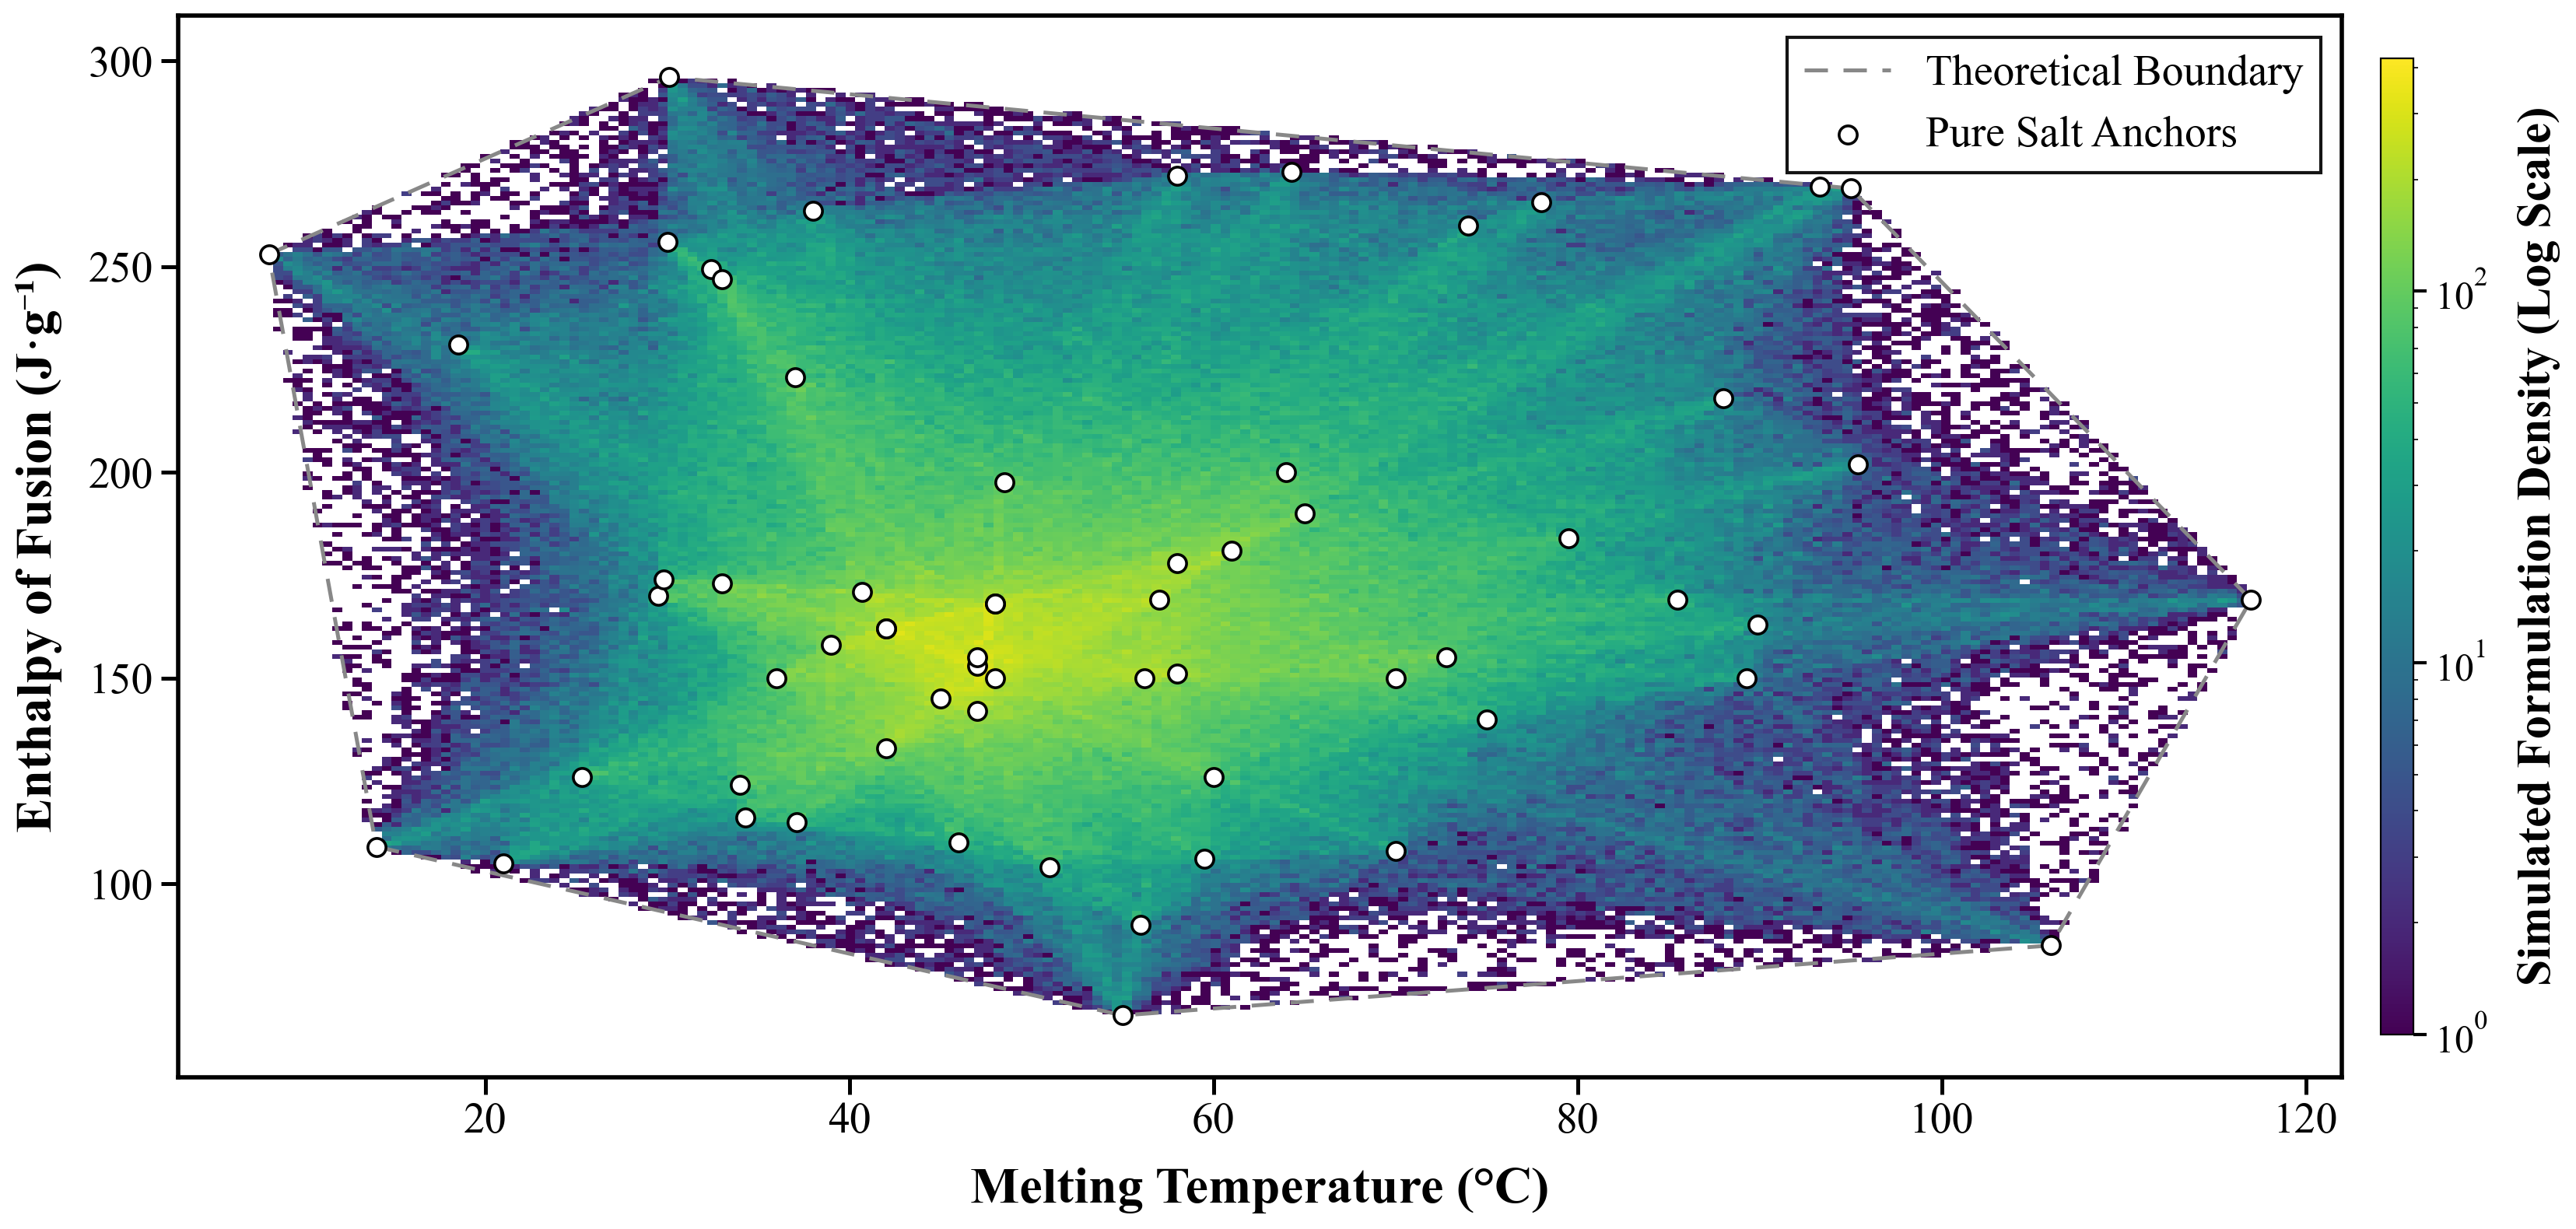

Salt count: 62
Sampled points: 1,000,000
[DONE] figure1_search_space_density.png
[DONE] figure1_search_space_density.pdf


In [1]:
# Figure 1: Tm-DH search-space density map
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.spatial import ConvexHull
from pathlib import Path

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.unicode_minus'] = False

base = Path('.')
df = pd.read_csv(base / 'hydrated_salts.csv')

tm_vals = df['Tm (°C)'].astype(float).to_numpy()
dh_vals = df['ΔHm (J/g)'].astype(float).to_numpy()
n_salts = len(df)

N = 1_000_000
rng = np.random.default_rng(42)
n_binary = int(N * 0.1)
n_ternary = N - n_binary

tm_samples = np.empty(N)
dh_samples = np.empty(N)

idx = rng.integers(0, n_salts, size=(n_binary, 2))
mask = idx[:, 0] == idx[:, 1]
while mask.any():
    idx[mask, 1] = rng.integers(0, n_salts, size=mask.sum())
    mask = idx[:, 0] == idx[:, 1]

w1 = rng.uniform(0.01, 0.99, size=n_binary)
w2 = 1.0 - w1
tm_samples[:n_binary] = w1 * tm_vals[idx[:, 0]] + w2 * tm_vals[idx[:, 1]]
dh_samples[:n_binary] = w1 * dh_vals[idx[:, 0]] + w2 * dh_vals[idx[:, 1]]

idx3 = rng.integers(0, n_salts, size=(n_ternary, 3))
dup = (idx3[:, 0] == idx3[:, 1]) | (idx3[:, 0] == idx3[:, 2]) | (idx3[:, 1] == idx3[:, 2])
while dup.any():
    idx3[dup] = rng.integers(0, n_salts, size=(dup.sum(), 3))
    dup = (idx3[:, 0] == idx3[:, 1]) | (idx3[:, 0] == idx3[:, 2]) | (idx3[:, 1] == idx3[:, 2])

r = rng.dirichlet([1, 1, 1], size=n_ternary)
r = np.clip(r, 0.01, None)
r /= r.sum(axis=1, keepdims=True)
tm_samples[n_binary:] = r[:, 0] * tm_vals[idx3[:, 0]] + r[:, 1] * tm_vals[idx3[:, 1]] + r[:, 2] * tm_vals[idx3[:, 2]]
dh_samples[n_binary:] = r[:, 0] * dh_vals[idx3[:, 0]] + r[:, 1] * dh_vals[idx3[:, 1]] + r[:, 2] * dh_vals[idx3[:, 2]]

fig, ax = plt.subplots(figsize=(18, 8), dpi=200)
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

hb = ax.hist2d(
    tm_samples,
    dh_samples,
    bins=[200, 200],
    cmap='viridis',
    norm=LogNorm(vmin=1, vmax=None),
    zorder=1,
)

cbar = fig.colorbar(hb[3], ax=ax, shrink=0.92, pad=0.015, aspect=30)
cbar.set_label('Simulated Formulation Density (Log Scale)', fontsize=22, fontweight='bold', labelpad=14)
cbar.ax.tick_params(labelsize=18, width=1.5, length=6)

pts = np.column_stack([tm_vals, dh_vals])
hull = ConvexHull(pts)
hull_verts = np.append(hull.vertices, hull.vertices[0])
ax.plot(
    pts[hull_verts, 0],
    pts[hull_verts, 1],
    color='#888888',
    linestyle='--',
    linewidth=1.8,
    dashes=(6, 4),
    zorder=5,
    label='Theoretical Boundary',
)

ax.scatter(
    tm_vals,
    dh_vals,
    s=70,
    facecolors='white',
    edgecolors='black',
    linewidths=1.3,
    zorder=10,
    label='Pure Salt Anchors',
)

ax.set_xlabel('Melting Temperature (°C)', fontsize=24, fontweight='bold', labelpad=12)
ax.set_ylabel('Enthalpy of Fusion (J·g⁻¹)', fontsize=24, fontweight='bold', labelpad=12)
ax.tick_params(axis='both', which='major', labelsize=20, length=8, width=1.8, direction='out')
ax.set_xlim(tm_vals.min() - 5, tm_vals.max() + 5)
ax.set_ylim(dh_vals.min() - 15, dh_vals.max() + 15)

for spine in ax.spines.values():
    spine.set_linewidth(2.0)

leg = ax.legend(loc='upper right', fontsize=20, framealpha=0.92, edgecolor='black', fancybox=False)
leg.get_frame().set_linewidth(1.5)

plt.tight_layout()
out_png = base / 'figure1_search_space_density.png'
out_pdf = base / 'figure1_search_space_density.pdf'
fig.savefig(out_png, dpi=350, bbox_inches='tight', facecolor='white')
fig.savefig(out_pdf, bbox_inches='tight', facecolor='white')
plt.show()

print(f'Salt count: {n_salts}')
print(f'Sampled points: {N:,}')
print('[DONE]', out_png)
print('[DONE]', out_pdf)


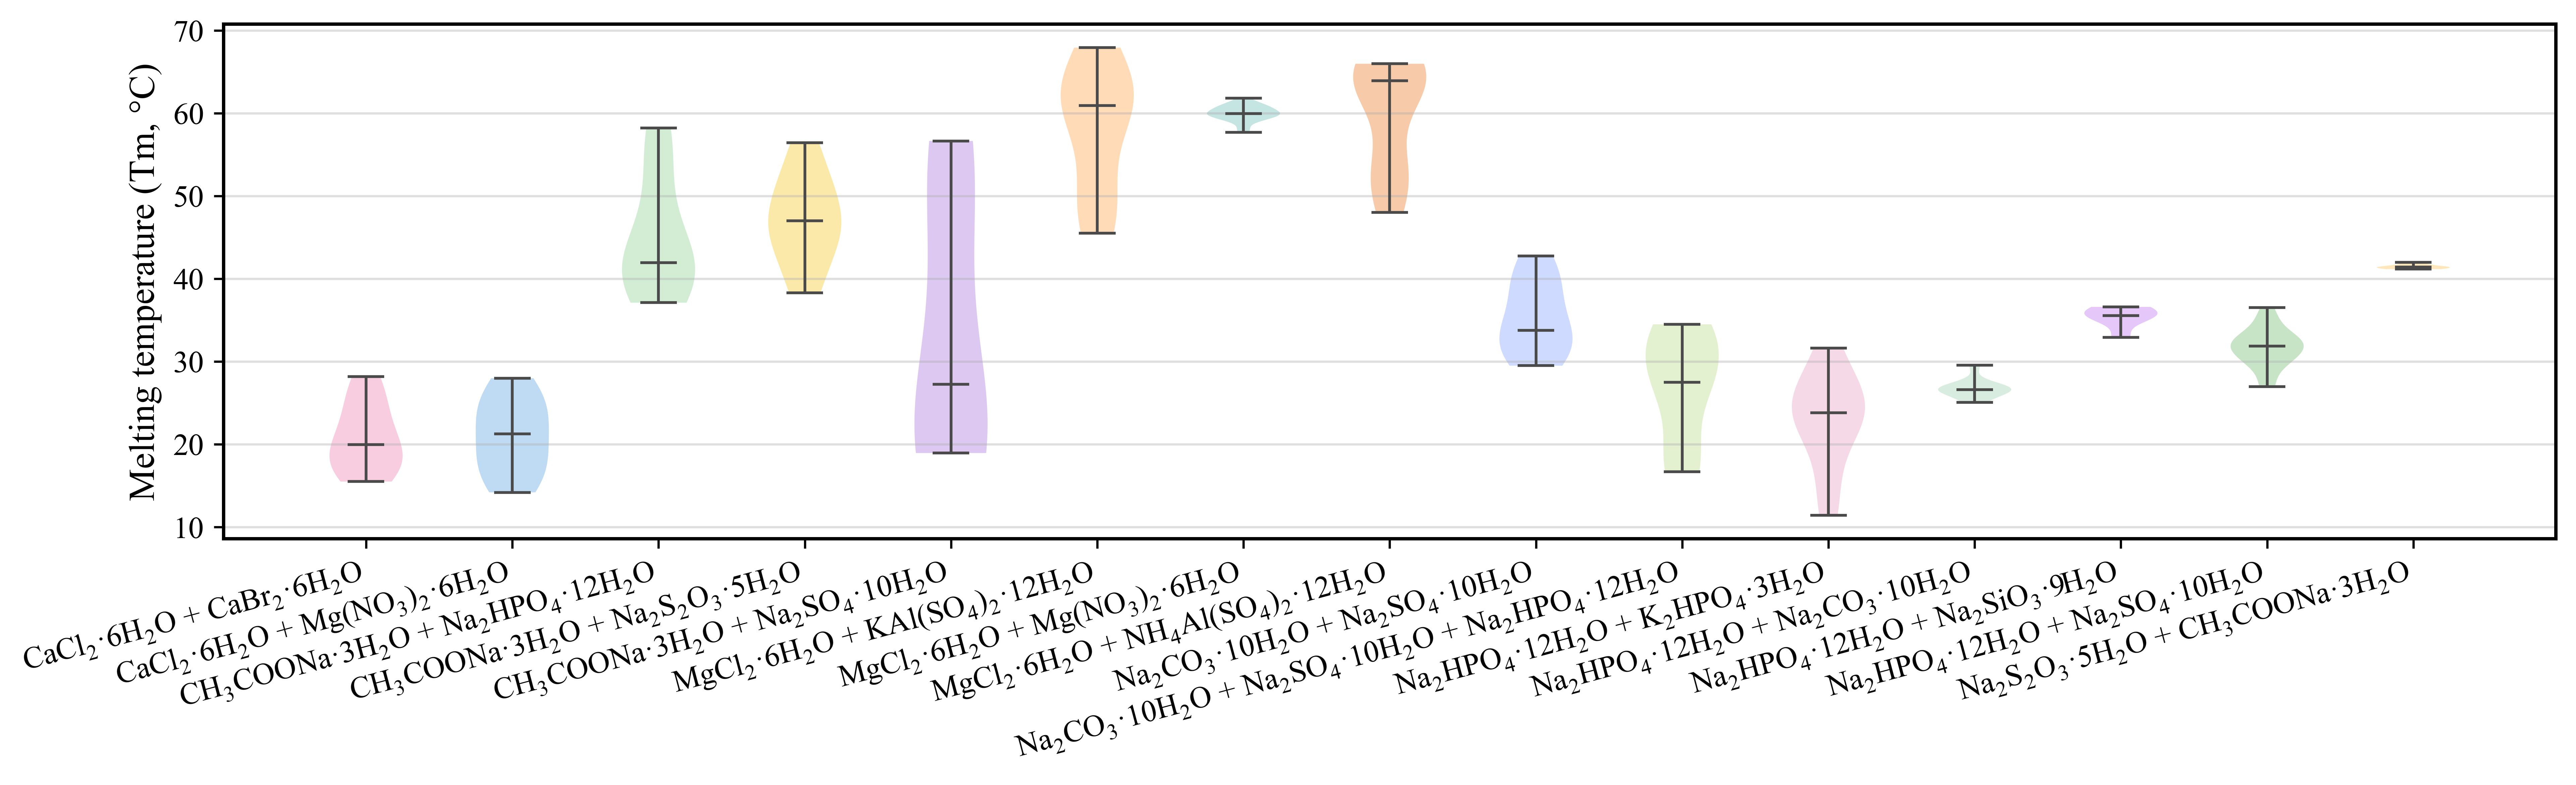

[DONE] figure2_tm_violin_top15.png
Systems plotted: 15


In [2]:
# Figure 2: Top-15 system violin plot — Melting temperature (Tm)
import re
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Times New Roman'
plt.rcParams['mathtext.it'] = 'Times New Roman:italic'
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11

base = Path('.')
df = pd.read_excel(base / 'eutectic_violin_data.xlsx')
df.columns = ['System', 'Tm', 'DeltaH']

top15_systems = df['System'].value_counts().head(15).index.tolist()
df_top = df[df['System'].isin(top15_systems)]
systems = df_top['System'].unique().tolist()

def smart_subscript(text):
    # Protect hydration numbers (e.g. ·6H2O) so they are not subscripted
    text = re.sub(r'·\d+H2O', lambda m: m.group(0).replace('·', '@@'), text)
    # Apply subscripts to element numbers
    text = re.sub(r'(?<=[A-Za-z)])(\d+)', lambda m: '$_{' + m.group(1) + '}$', text)
    text = text.replace('@@', '·')
    return text

systems_labels = [smart_subscript(s.replace('+', ' + ')) for s in systems]

macaron_colors = [
    '#F8C8DC', '#B7D7F2', '#CDECCF', '#FBE7A1', '#D9C2F0',
    '#FFD8B1', '#BFE3E0', '#F7C5A0', '#C9D6FF', '#E2F0CB',
    '#F6D5E5', '#D4ECDD', '#E4C1F9', '#C1E1C1', '#FFE5B4',
]
violin_colors = [macaron_colors[i % len(macaron_colors)] for i in range(len(systems))]

fig, ax = plt.subplots(figsize=(13, 4), dpi=600)
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

data_plot = [df_top[df_top['System'] == s]['Tm'].dropna() for s in systems]
vp = ax.violinplot(data_plot, showmeans=False, showmedians=True, showextrema=True)

for i, body in enumerate(vp['bodies']):
    body.set_facecolor(violin_colors[i])
    body.set_edgecolor('none')
    body.set_linewidth(0.0)
    body.set_alpha(0.9)

for key in ['cmedians', 'cbars', 'cmins', 'cmaxes']:
    vp[key].set_edgecolor('#4A4A4A')
    vp[key].set_linewidth(1.0)

ax.set_xticks(range(1, len(systems_labels) + 1))
ax.set_xticklabels(systems_labels, rotation=15, ha='right')
ax.set_ylabel('Melting temperature (Tm, °C)', fontsize=13)
ax.grid(True, axis='y', alpha=0.4)

plt.tight_layout()
out_png = base / 'figure2_tm_violin_top15.png'
out_pdf = base / 'figure2_tm_violin_top15.pdf'
plt.savefig(out_png, dpi=600, bbox_inches='tight', facecolor='white')
plt.savefig(out_pdf, bbox_inches='tight', facecolor='white')
plt.show()

print('[DONE]', out_png)
print('Systems plotted:', len(systems))

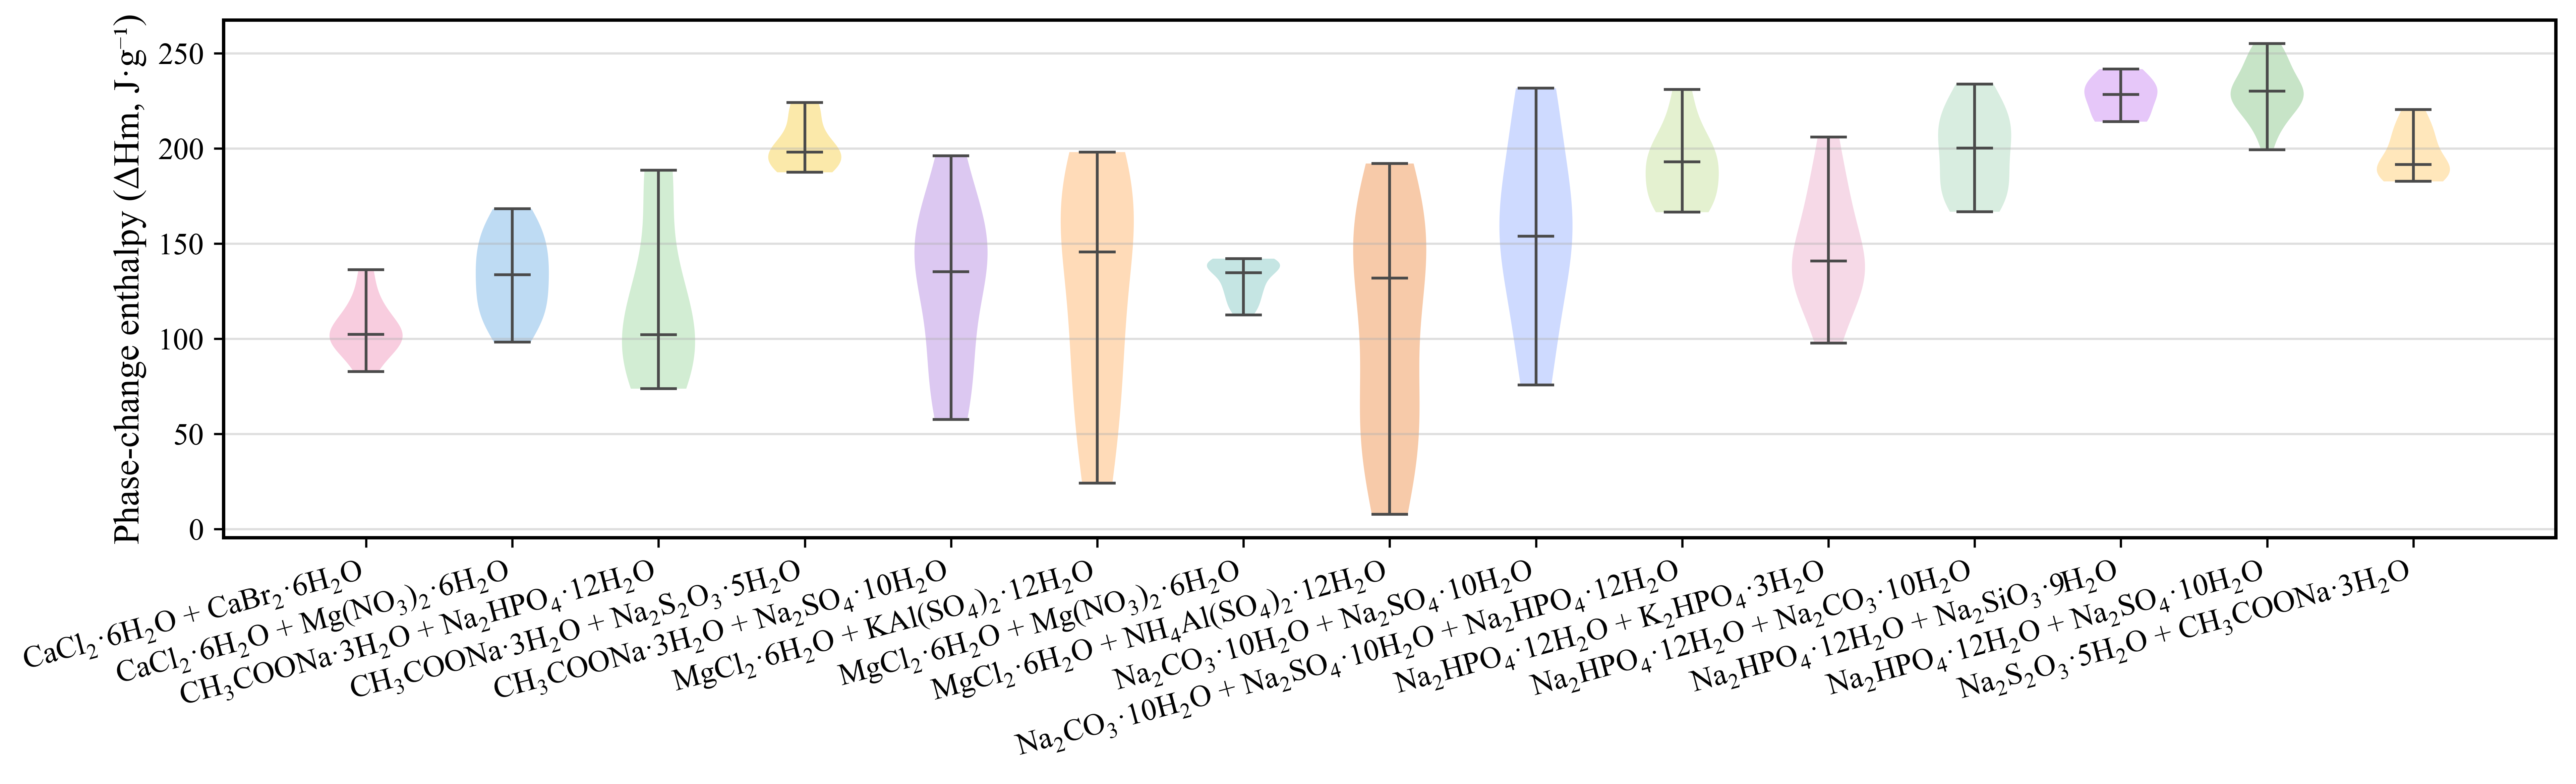

[DONE] figure3_dh_violin_top15.png
Systems plotted: 15


In [3]:
# Figure 3: Top-15 system violin plot — Phase-change enthalpy (ΔHm)
import re
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'custom'
plt.rcParams['mathtext.rm'] = 'Times New Roman'
plt.rcParams['mathtext.it'] = 'Times New Roman:italic'
plt.rcParams['mathtext.bf'] = 'Times New Roman:bold'
plt.rcParams['axes.linewidth'] = 1.2
plt.rcParams['xtick.labelsize'] = 11
plt.rcParams['ytick.labelsize'] = 11

base = Path('.')
df = pd.read_excel(base / 'eutectic_violin_data.xlsx')
df.columns = ['System', 'Tm', 'DeltaH']

top15_systems = df['System'].value_counts().head(15).index.tolist()
df_top = df[df['System'].isin(top15_systems)]
systems = df_top['System'].unique().tolist()

def smart_subscript(text):
    # Protect hydration numbers (e.g. ·6H2O) so they are not subscripted
    text = re.sub(r'·\d+H2O', lambda m: m.group(0).replace('·', '@@'), text)
    # Apply subscripts to element numbers
    text = re.sub(r'(?<=[A-Za-z)])(\d+)', lambda m: '$_{' + m.group(1) + '}$', text)
    text = text.replace('@@', '·')
    return text

systems_labels = [smart_subscript(s.replace('+', ' + ')) for s in systems]

macaron_colors = [
    '#F8C8DC', '#B7D7F2', '#CDECCF', '#FBE7A1', '#D9C2F0',
    '#FFD8B1', '#BFE3E0', '#F7C5A0', '#C9D6FF', '#E2F0CB',
    '#F6D5E5', '#D4ECDD', '#E4C1F9', '#C1E1C1', '#FFE5B4',
]
violin_colors = [macaron_colors[i % len(macaron_colors)] for i in range(len(systems))]

fig, ax = plt.subplots(figsize=(13, 4), dpi=600)
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

data_plot = [df_top[df_top['System'] == s]['DeltaH'].dropna() for s in systems]
vp = ax.violinplot(data_plot, showmeans=False, showmedians=True, showextrema=True)

for i, body in enumerate(vp['bodies']):
    body.set_facecolor(violin_colors[i])
    body.set_edgecolor('none')
    body.set_linewidth(0.0)
    body.set_alpha(0.9)

for key in ['cmedians', 'cbars', 'cmins', 'cmaxes']:
    vp[key].set_edgecolor('#4A4A4A')
    vp[key].set_linewidth(1.0)

ax.set_xticks(range(1, len(systems_labels) + 1))
ax.set_xticklabels(systems_labels, rotation=15, ha='right')
ax.set_ylabel('Phase-change enthalpy (ΔHm, J·g⁻¹)', fontsize=13)
ax.grid(True, axis='y', alpha=0.4)

plt.tight_layout()
out_png = base / 'figure3_dh_violin_top15.png'
out_pdf = base / 'figure3_dh_violin_top15.pdf'
plt.savefig(out_png, dpi=600, bbox_inches='tight', facecolor='white')
plt.savefig(out_pdf, bbox_inches='tight', facecolor='white')
plt.show()

print('[DONE]', out_png)
print('Systems plotted:', len(systems))

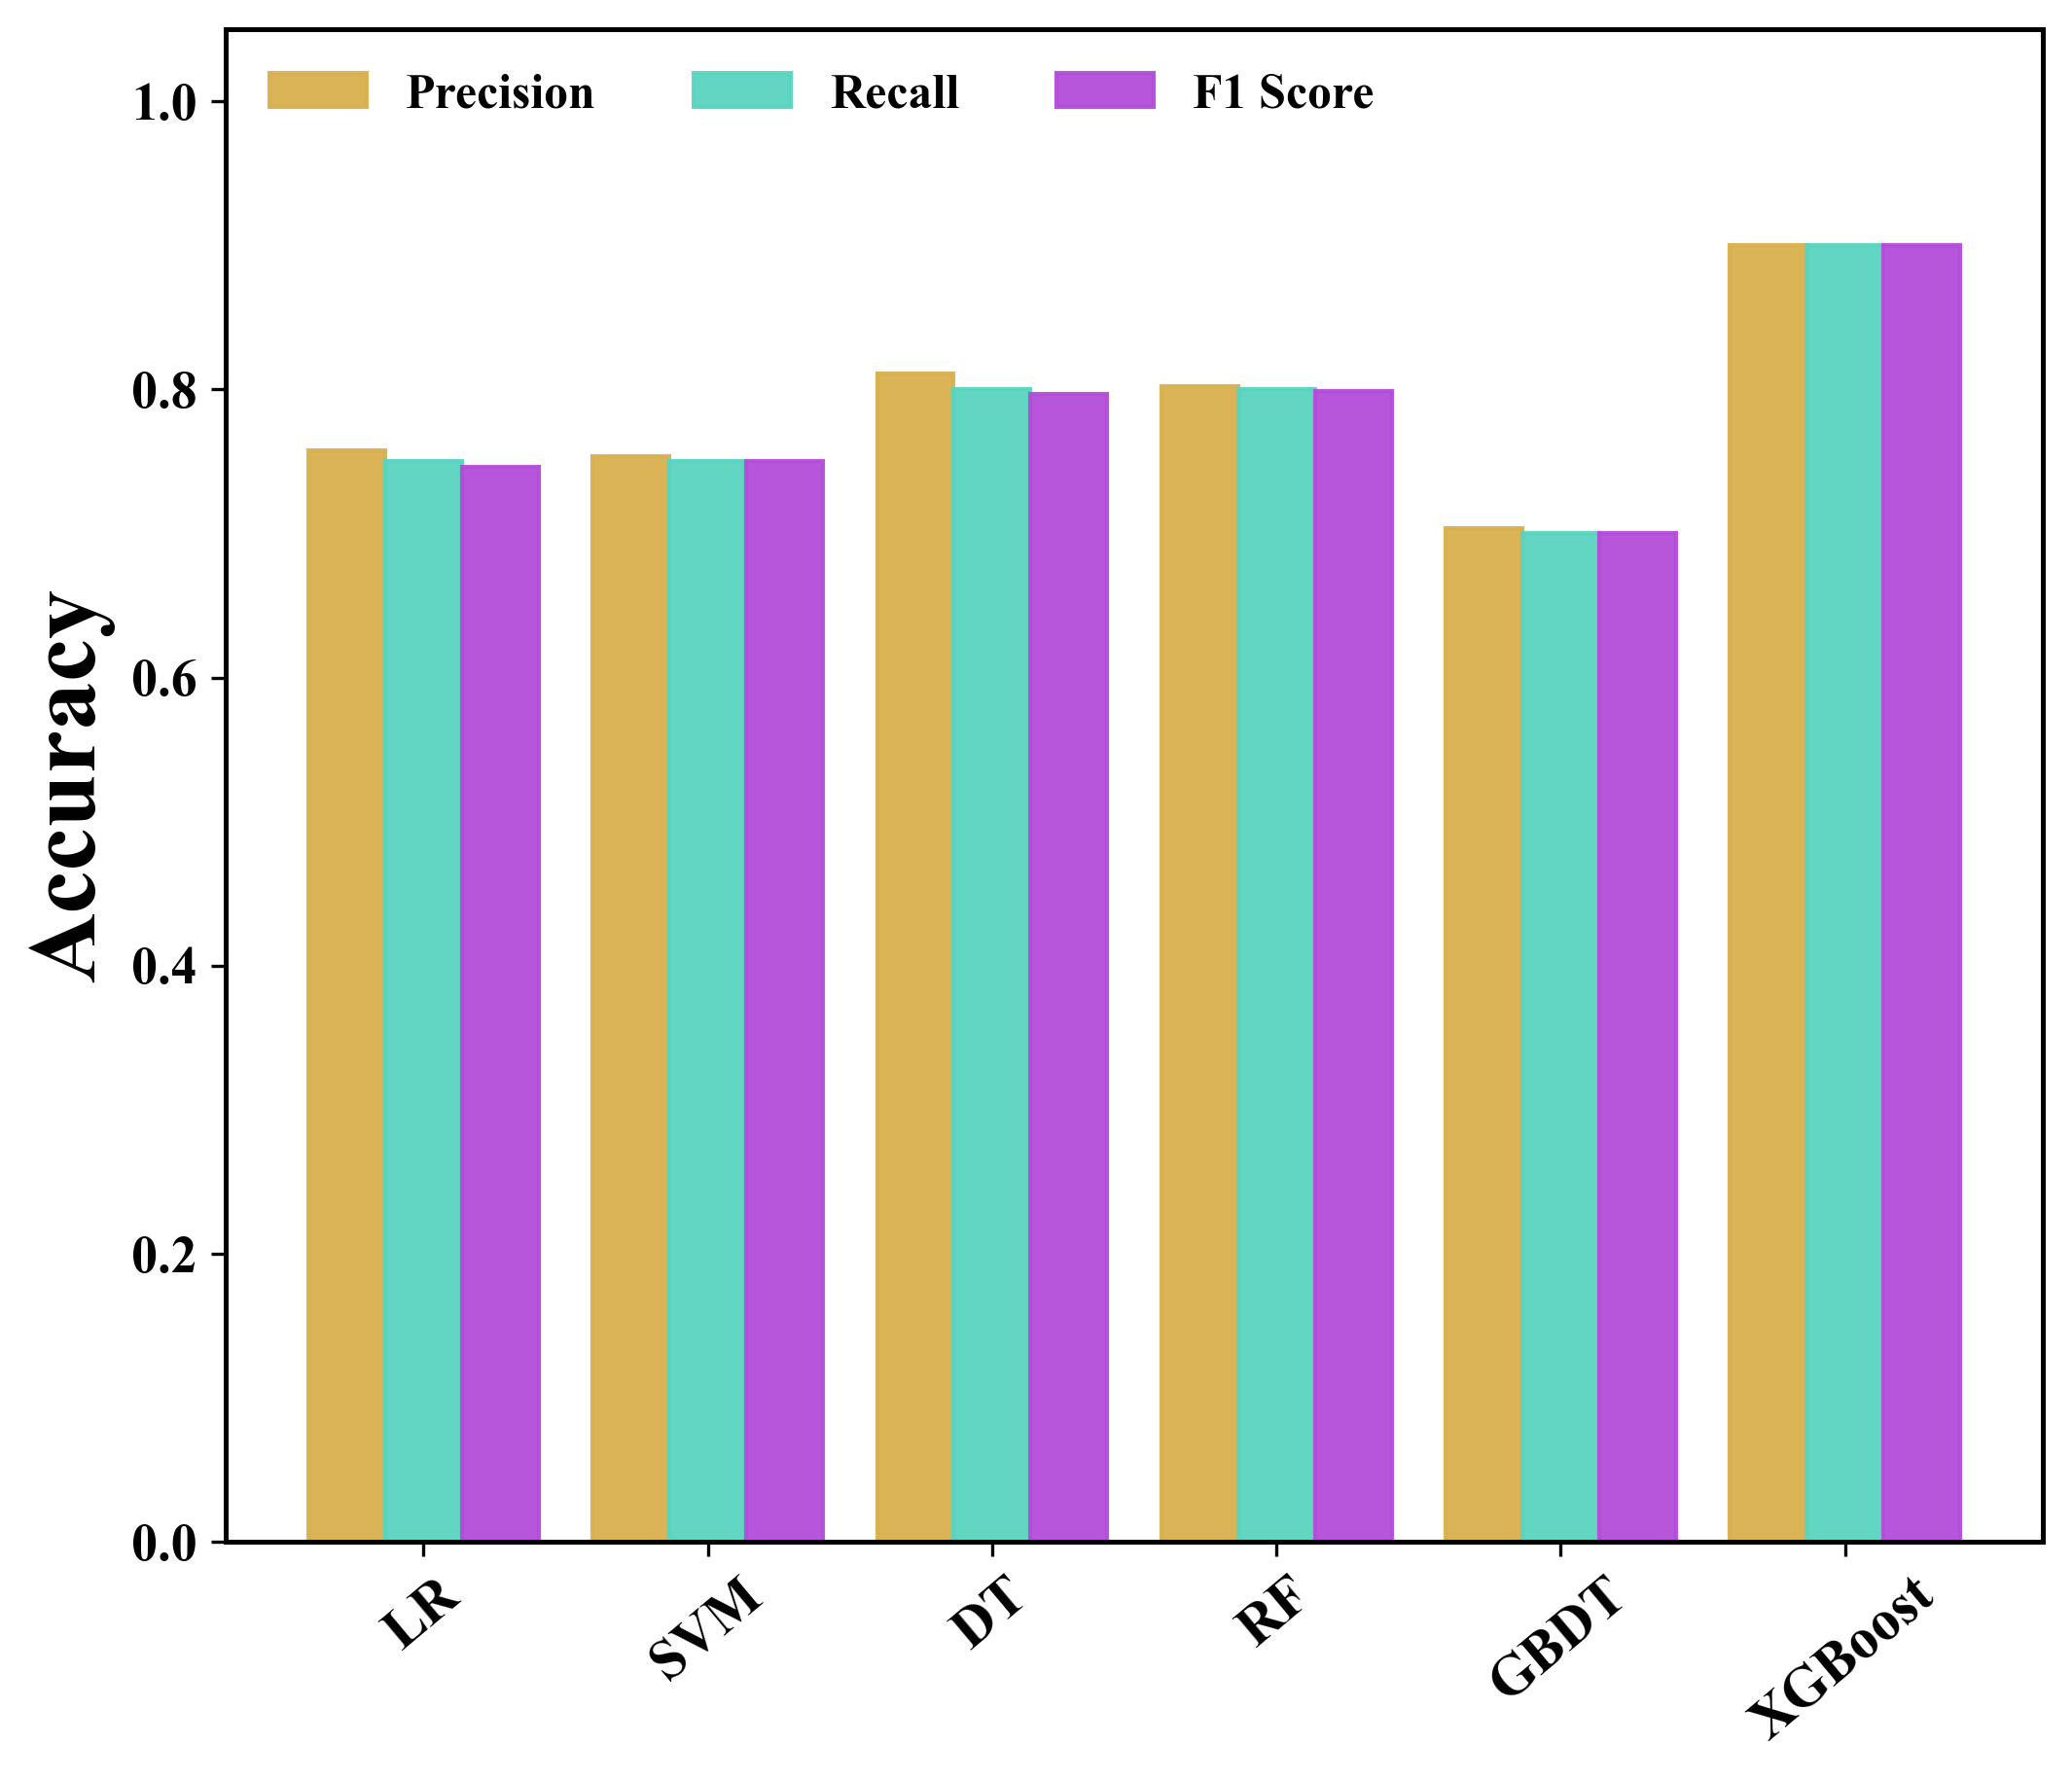

[DONE] figure4_singlepeak_prf_bar.png
  model  precision  recall     f1
     LR     0.7580    0.75 0.7462
    SVM     0.7538    0.75 0.7500
     DT     0.8107    0.80 0.7969
     RF     0.8020    0.80 0.7990
   GBDT     0.7035    0.70 0.7000
XGBoost     0.9000    0.90 0.9000


In [4]:
# Figure 4: Precision / Recall / F1 bar chart for single-peak classification models
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.weight'] = 'bold'
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.unicode_minus'] = False

base = Path('.')
result_df = pd.read_csv(base / 'singlepeak_model_results.csv', encoding='utf-8-sig')

wanted_order = ['LR', 'SVM', 'DT', 'RF', 'GBDT', 'XGBoost']
plot_df = result_df.set_index('model').reindex(wanted_order).reset_index()

x = np.arange(len(plot_df))
width = 0.27

precision_vals = plot_df['precision'].values
recall_vals    = plot_df['recall'].values
f1_vals        = plot_df['f1'].values

fig, ax = plt.subplots(figsize=(7.2, 6.2), dpi=300)
ax.bar(x - width, precision_vals, width=width,
       color='#d8b04d', edgecolor='#d8b04d', label='Precision', alpha=0.95)
ax.bar(x,          recall_vals,    width=width,
       color='#59d4bf', edgecolor='#59d4bf', label='Recall',    alpha=0.95)
ax.bar(x + width,  f1_vals,        width=width,
       color='#b34dd9', edgecolor='#b34dd9', label='F1 Score',  alpha=0.95)

ax.set_xticks(x)
ax.set_xticklabels(wanted_order, rotation=40, fontsize=14, fontweight='bold')
ax.tick_params(axis='y', labelsize=13)
for label in ax.get_yticklabels():
    label.set_fontweight('bold')
ax.set_ylim(0, 1.05)
ax.set_ylabel('Accuracy', fontsize=24, fontweight='bold')
ax.legend(loc='upper left', frameon=False, ncol=3, fontsize=12)

plt.tight_layout()
out_png = base / 'figure4_singlepeak_prf_bar.png'
out_pdf = base / 'figure4_singlepeak_prf_bar.pdf'
fig.savefig(out_png, dpi=300, bbox_inches='tight')
fig.savefig(out_pdf, bbox_inches='tight')
plt.show()

print('[DONE]', out_png)
print(plot_df[['model', 'precision', 'recall', 'f1']].round(4).to_string(index=False))

Rule-Based Pipeline: 1074 rows
LLM Sequential Pipeline: 1002 rows
LLM Joint-Selection Pipeline: 7 rows


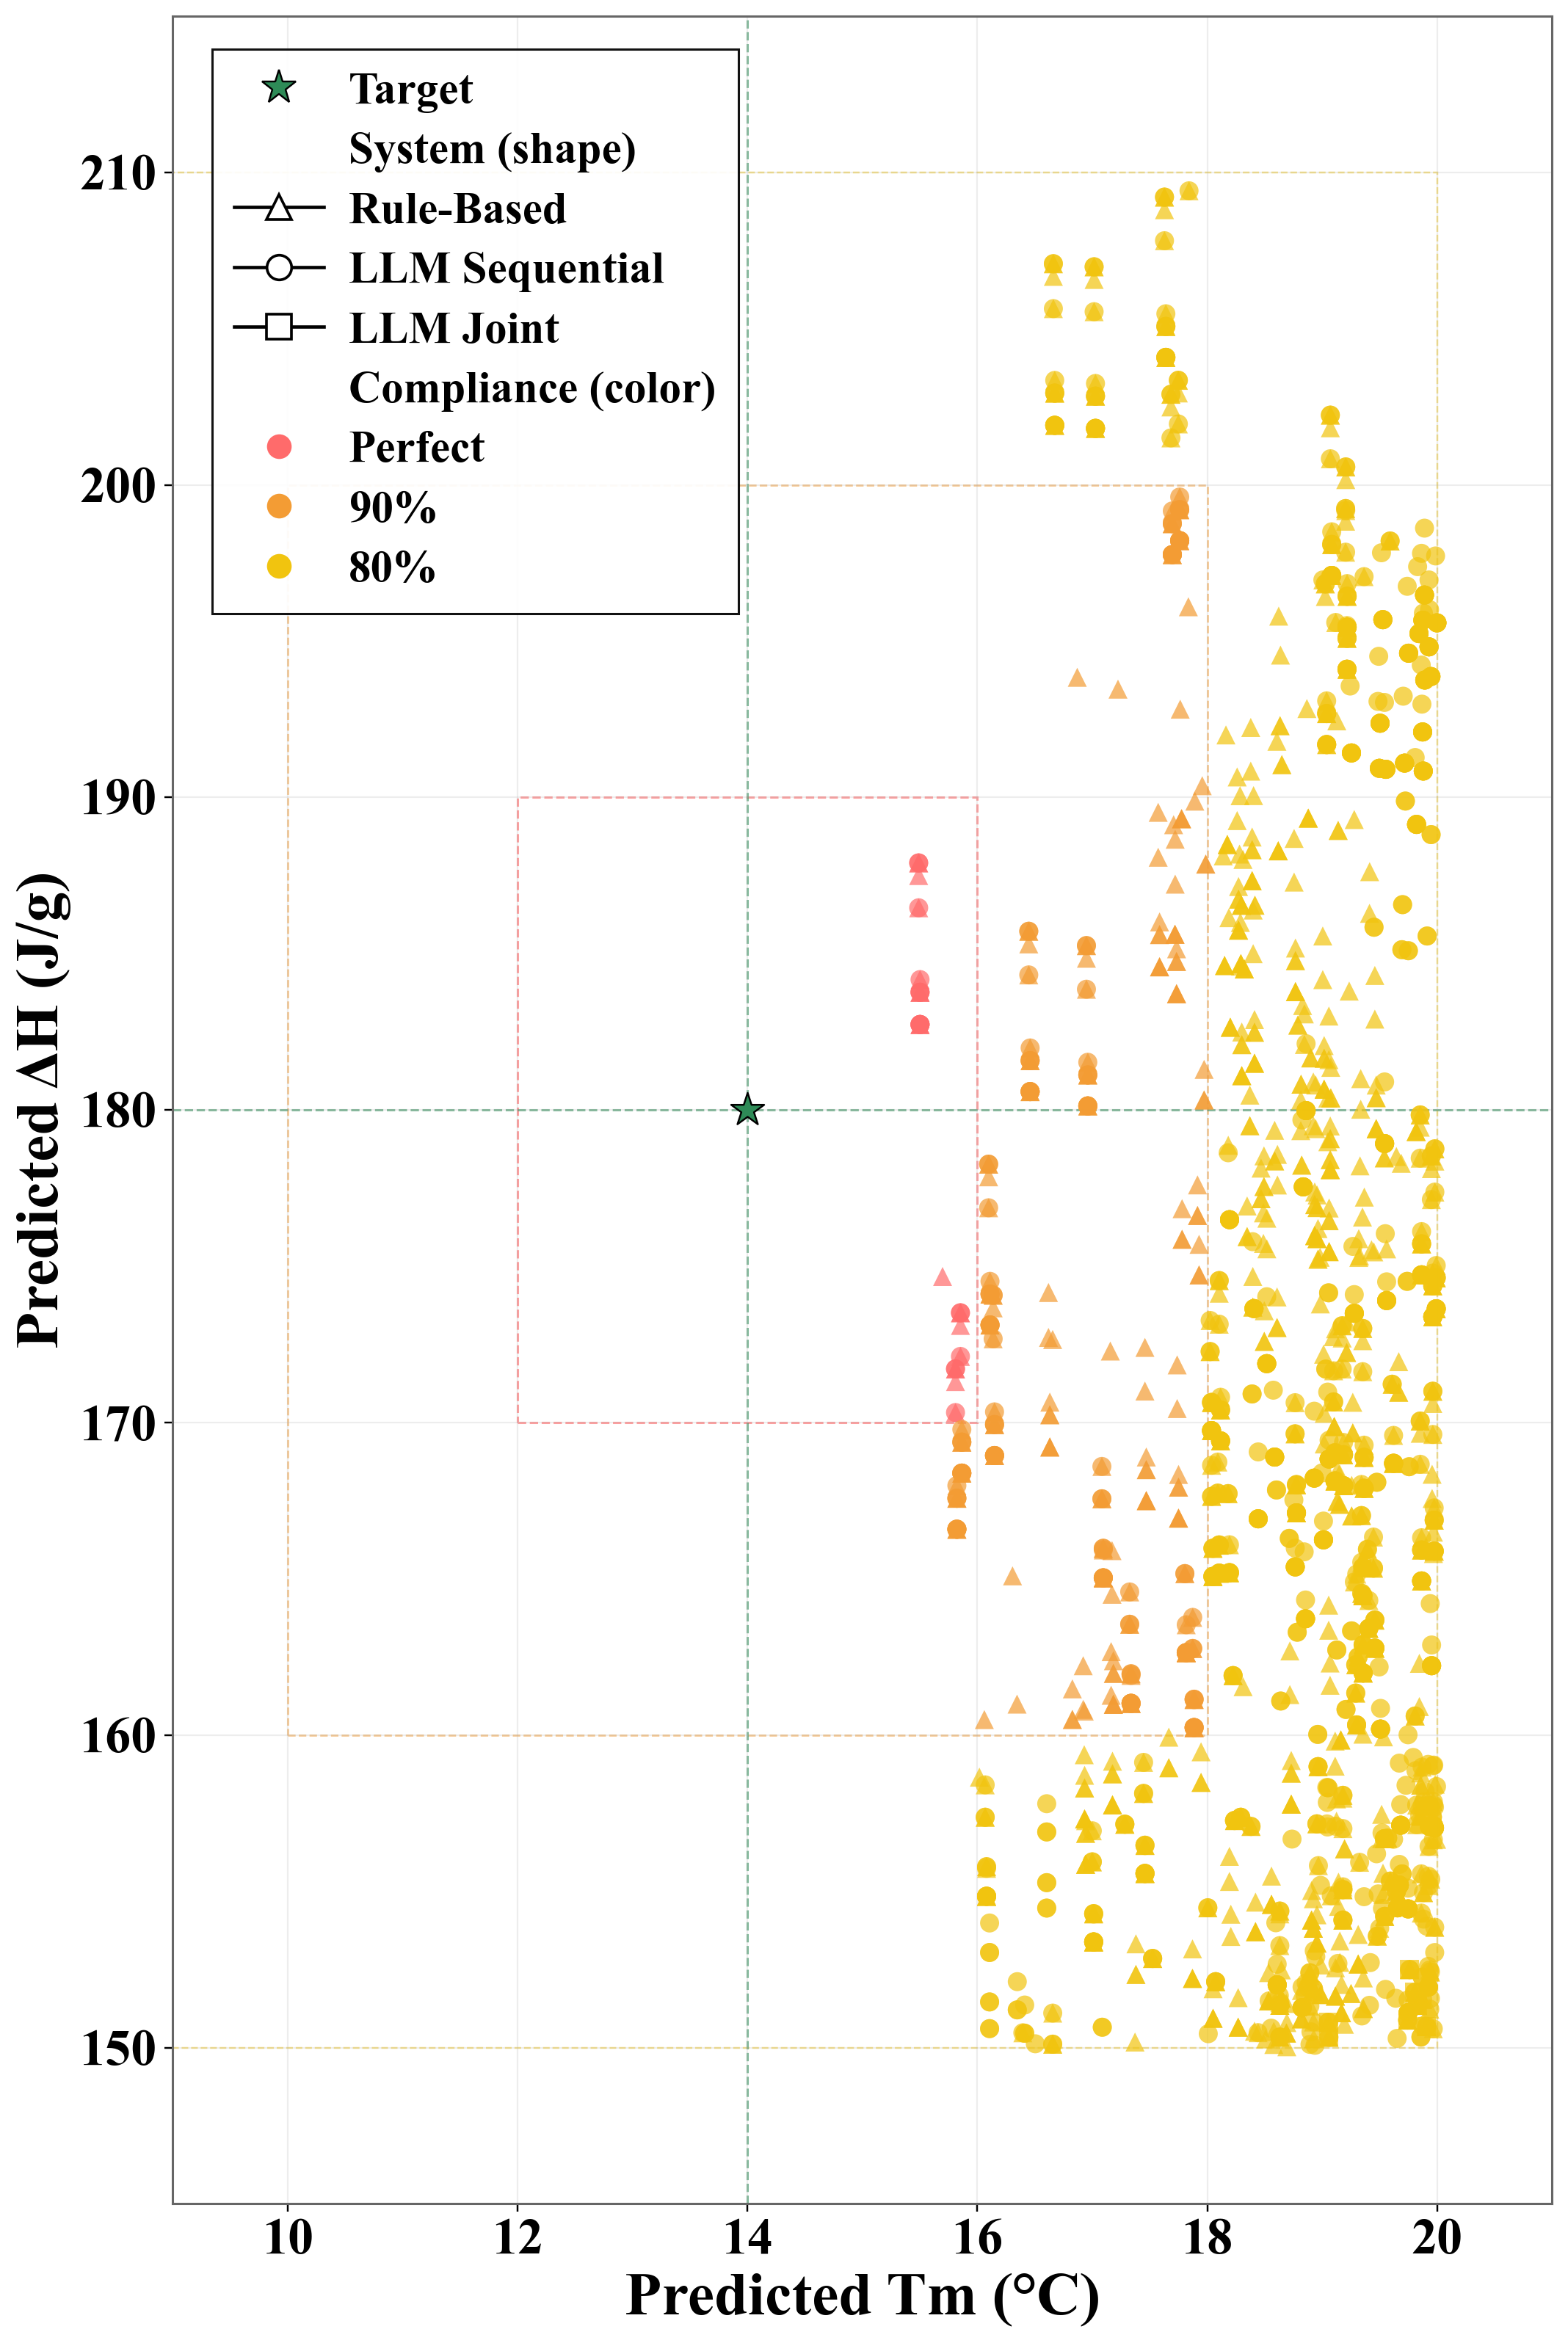

[DONE] figure5_tm_dh_three_systems.png


In [5]:
# Figure 5: Three-system predicted Tm vs. predicted DH scatter plot
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from pathlib import Path

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 23
plt.rcParams['axes.labelsize'] = 27
plt.rcParams['xtick.labelsize'] = 23
plt.rcParams['ytick.labelsize'] = 23
plt.rcParams['legend.fontsize'] = 20

base = Path('.')

datasets = [
    {'name': 'Rule-Based Pipeline',          'file': 'tm_dh_rule_based.csv',    'marker': '^'},
    {'name': 'LLM Sequential Pipeline',      'file': 'tm_dh_llm_sequential.csv','marker': 'o'},
    {'name': 'LLM Joint-Selection Pipeline', 'file': 'tm_dh_llm_joint.csv',     'marker': 's'},
]

level_to_color = {1.0: '#ff6b6b', 0.9: '#f39c34', 0.8: '#f1c40f'}
target_tm, target_dh = 14.0, 180.0

def level_mask(df, level, tol=1e-6):
    return (df['compliance_level'] - level).abs() <= tol

loaded = []
for item in datasets:
    df = pd.read_csv(base / item['file'])
    df['tm_pred'] = pd.to_numeric(df['tm_pred'], errors='coerce')
    df['dh_pred'] = pd.to_numeric(df['dh_pred'], errors='coerce')
    df['compliance_level'] = pd.to_numeric(df['compliance_level'], errors='coerce')
    df = df.dropna(subset=['tm_pred', 'dh_pred', 'compliance_level']).reset_index(drop=True)
    loaded.append((item, df))
    print(f"{item['name']}: {len(df)} rows")

fig, ax = plt.subplots(figsize=(10.2, 15), dpi=220)
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# Tolerance zone rectangles
ax.add_patch(Rectangle((12, 170), 4, 20, lw=1.0, edgecolor='#ff6b6b',
             facecolor='none', linestyle='--', alpha=0.65, zorder=1))
ax.add_patch(Rectangle((10, 160), 8, 40, lw=0.9, edgecolor='#f39c34',
             facecolor='none', linestyle='--', alpha=0.55, zorder=1))
ax.add_patch(Rectangle(( 8, 150), 12, 60, lw=0.8, edgecolor='#f1c40f',
             facecolor='none', linestyle='--', alpha=0.50, zorder=1))

# Target reference lines and marker
ax.axvline(target_tm, color='#2e8b57', linestyle='--', lw=1.0, alpha=0.6, zorder=1)
ax.axhline(target_dh, color='#2e8b57', linestyle='--', lw=1.0, alpha=0.6, zorder=1)
ax.scatter(target_tm, target_dh, s=240, marker='*', c='#2e8b57',
           edgecolors='black', linewidths=0.8, zorder=8)

# Data points: color = compliance level, shape = pipeline system
for item, df in loaded:
    for level in (1.0, 0.9, 0.8):
        sub = df[level_mask(df, level)]
        if sub.empty:
            continue
        ax.scatter(sub['tm_pred'], sub['dh_pred'],
                   s=72, marker=item['marker'], c=level_to_color[level],
                   alpha=0.70, edgecolors='none', zorder=3)

ax.set_xlabel('Predicted Tm (\u00b0C)', fontweight='bold')
ax.set_ylabel('Predicted \u0394H (J/g)', fontweight='bold')
ax.set_xlim(9, 21)
ax.set_ylim(145, 215)
ax.grid(True, alpha=0.22, linewidth=0.7)
for spine in ax.spines.values():
    spine.set_linewidth(1.0)
    spine.set_color('#666666')
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontweight('bold')

# Legend: shapes for pipeline, colors for compliance level
legend_handles = [
    Line2D([0], [0], marker='*', color='w', markerfacecolor='#2e8b57',
           markeredgecolor='black', markeredgewidth=0.8, markersize=16, label='Target'),
    Line2D([0], [0], linestyle='None', color='none', label='System (shape)'),
    Line2D([0], [0], marker='^', color='black', markerfacecolor='white',
           markeredgecolor='black', markeredgewidth=1.2, markersize=11, label='Rule-Based'),
    Line2D([0], [0], marker='o', color='black', markerfacecolor='white',
           markeredgecolor='black', markeredgewidth=1.2, markersize=11, label='LLM Sequential'),
    Line2D([0], [0], marker='s', color='black', markerfacecolor='white',
           markeredgecolor='black', markeredgewidth=1.2, markersize=11, label='LLM Joint'),
    Line2D([0], [0], linestyle='None', color='none', label='Compliance (color)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#ff6b6b',
           markeredgecolor='none', markersize=11, label='Perfect'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#f39c34',
           markeredgecolor='none', markersize=11, label='90%'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#f1c40f',
           markeredgecolor='none', markersize=11, label='80%'),
]
legend = ax.legend(
    handles=legend_handles,
    loc='upper left', bbox_to_anchor=(0.012, 0.995),
    frameon=True, fancybox=False, edgecolor='black', framealpha=0.93,
    borderpad=0.5, labelspacing=0.42, handletextpad=0.55,
    prop={'family': 'Times New Roman', 'size': 20, 'weight': 'bold'},
)
for text in legend.get_texts():
    if text.get_text() in {'System (shape)', 'Compliance (color)'}:
        text.set_weight('bold')

plt.tight_layout()
out_png = base / 'figure5_tm_dh_three_systems.png'
out_pdf = base / 'figure5_tm_dh_three_systems.pdf'
fig.savefig(out_png, dpi=450, bbox_inches='tight')
fig.savefig(out_pdf, bbox_inches='tight')
plt.show()

print('[DONE]', out_png)

Literature points: 48
Target points:     2
[SKIP] ternary raw: file not found -> ternary_full_predictions.csv
[SKIP] binary raw: file not found -> binary_full_predictions.csv
[SKIP] ternary filtered: file not found -> ternary_full_predictions_filtered.csv
[SKIP] binary filtered: file not found -> binary_full_predictions_filtered.csv


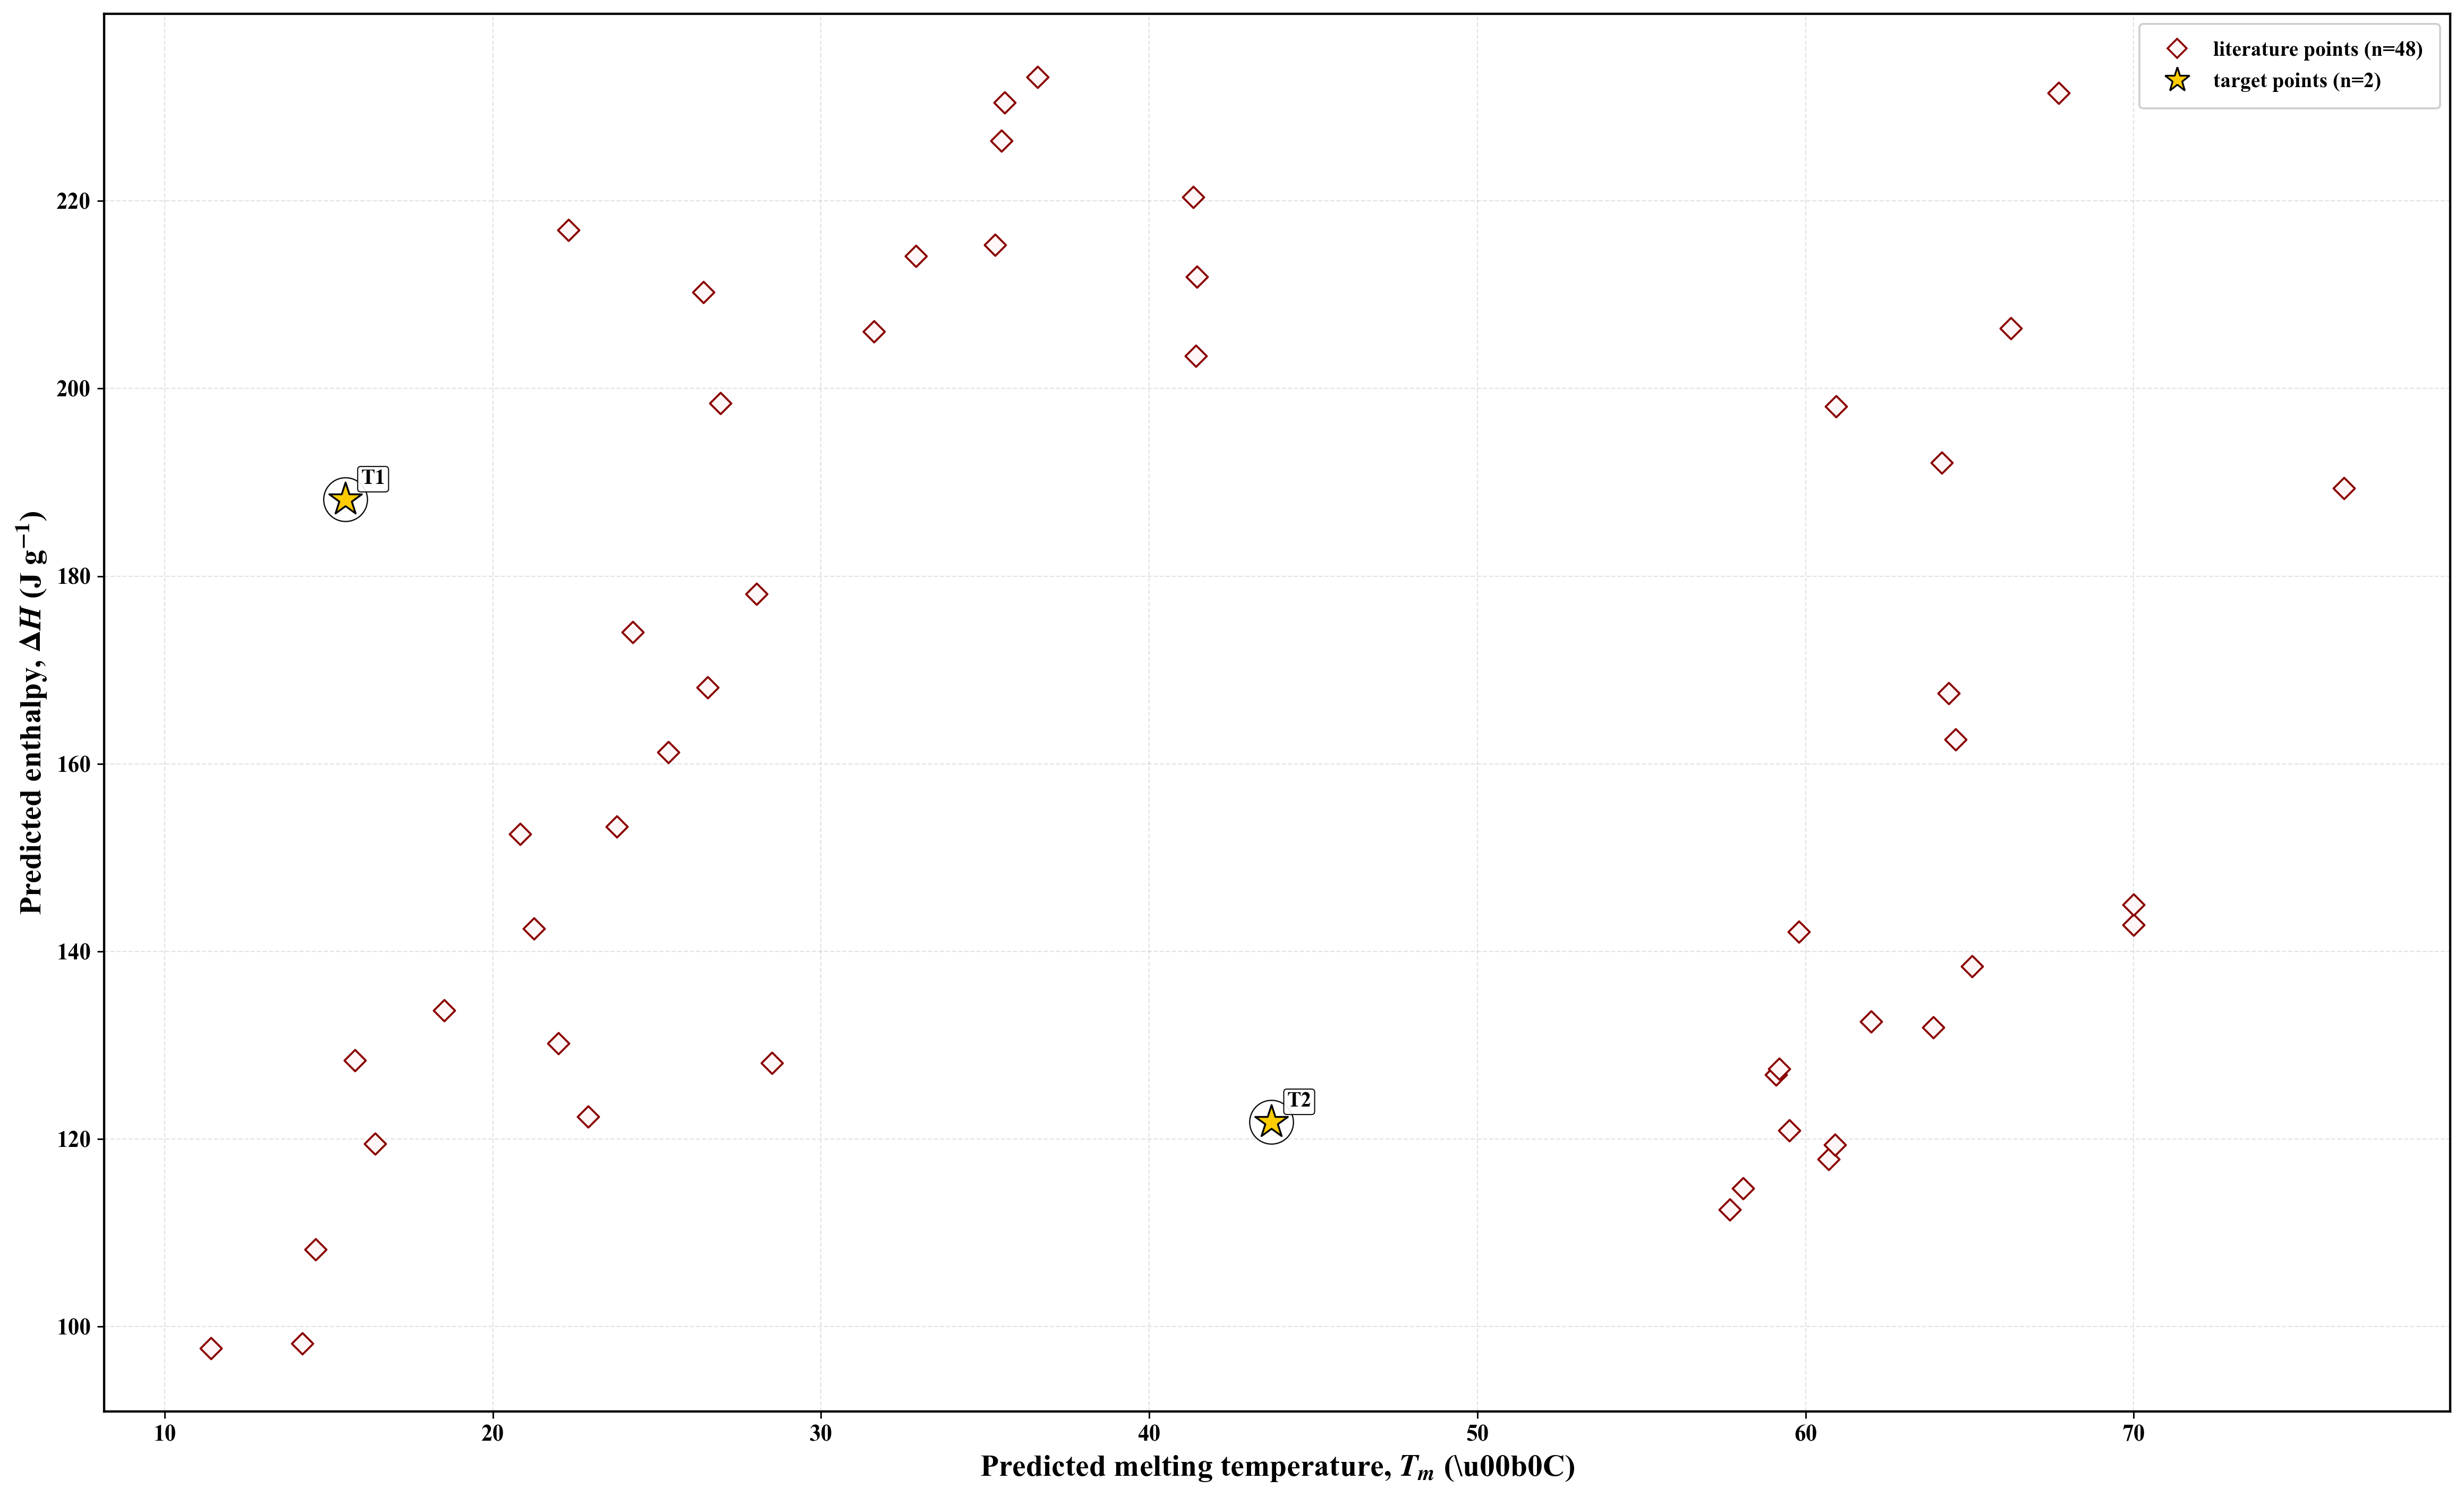

[DONE] figure6_prediction_space.png


In [ ]:
# Figure 6: Binary and Ternary Prediction Space — Raw vs. Filtered
# -----------------------------------------------------------------------
# NOTE: The four large CSV files below are NOT bundled in this repository
# due to their size (~100 GB total). 
# 
#   binary_full_predictions.csv            (~212 k rows,  ~200 MB)
#   ternary_full_predictions.csv           (~183 M rows,  large )
#   binary_full_predictions_filtered.csv   (~104 k rows,  ~100 MB)
#   ternary_full_predictions_filtered.csv  (~80 M rows,   large )
#
# The literature and target-point Excel files ARE included:
#   literature_data.xlsx    (n=48)
#   target_points.xlsx      (n=2)
# -----------------------------------------------------------------------

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from pathlib import Path

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'axes.unicode_minus': False,
    'font.size': 12,
    'axes.labelsize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 11,
})

base = Path('.')

DATA_FILES = {
    'binary raw':        base / 'binary_full_predictions.csv',
    'ternary raw':       base / 'ternary_full_predictions.csv',
    'binary filtered':   base / 'binary_full_predictions_filtered.csv',
    'ternary filtered':  base / 'ternary_full_predictions_filtered.csv',
}

PLOT_STYLES = {
    'ternary raw':     {'marker': '^', 's': 8.0,  'alpha': 0.16, 'c': '#7fb3d5', 'edgecolors': 'none', 'linewidths': 0.0, 'zorder': 1},
    'binary raw':      {'marker': 'o', 's': 7.0,  'alpha': 0.20, 'c': '#b7b7b7', 'edgecolors': 'none', 'linewidths': 0.0, 'zorder': 2},
    'ternary filtered':{'marker': '^', 's': 11.0, 'alpha': 0.52, 'c': '#1f77b4', 'edgecolors': 'none', 'linewidths': 0.0, 'zorder': 3},
    'binary filtered': {'marker': 'o', 's': 18.0, 'alpha': 0.84, 'c': '#d62728', 'edgecolors': 'none', 'linewidths': 0.18,'zorder': 4},
}

DRAW_ORDER = ['ternary raw', 'binary raw', 'ternary filtered', 'binary filtered']
CHUNK_SIZE = 300_000
X_COL, Y_COL = 'tm_pred', 'dh_pred'

def load_excel_points(path, tm_col, dh_col):
    df = pd.read_excel(path)
    out = df[[tm_col, dh_col]].copy()
    out.columns = ['x', 'y']
    out['x'] = pd.to_numeric(out['x'], errors='coerce')
    out['y'] = pd.to_numeric(out['y'], errors='coerce')
    return out.dropna().reset_index(drop=True)

lit_df = load_excel_points(base / 'literature_data.xlsx', 'Tm', 'enthalpy')
tgt_df = load_excel_points(base / 'target_points.xlsx',   'tm_pred', 'dh_pred')
print(f'Literature points: {len(lit_df)}')
print(f'Target points:     {len(tgt_df)}')

fig, ax = plt.subplots(figsize=(18, 11), dpi=260)

counts = {}
for label in DRAW_ORDER:
    csv_path = DATA_FILES[label]
    if not csv_path.exists():
        print(f'[SKIP] {label}: file not found -> {csv_path}')
        counts[label] = 0
        continue
    style = PLOT_STYLES[label]
    n = 0
    for chunk in pd.read_csv(csv_path, usecols=[X_COL, Y_COL],
                              chunksize=CHUNK_SIZE, low_memory=True):
        x = pd.to_numeric(chunk[X_COL], errors='coerce')
        y = pd.to_numeric(chunk[Y_COL], errors='coerce')
        valid = pd.DataFrame({'x': x, 'y': y}).dropna()
        if valid.empty:
            continue
        ax.scatter(valid['x'].to_numpy(), valid['y'].to_numpy(),
                   rasterized=True, **style)
        n += len(valid)
    counts[label] = n
    print(f'[OK] {label}: {n:,} points')

# Literature overlay (white halo + red diamond)
if not lit_df.empty:
    ax.scatter(lit_df['x'], lit_df['y'], marker='o', s=62*1.55, alpha=1.0,
               c='white', edgecolors='none', zorder=7, rasterized=True)
    ax.scatter(lit_df['x'], lit_df['y'], marker='D', s=62, alpha=1.0,
               c='#fff7f7', edgecolors='#8b0000', linewidths=1.05, zorder=8, rasterized=True)

# Target overlay (white halo + gold star + annotation)
if not tgt_df.empty:
    ax.scatter(tgt_df['x'], tgt_df['y'], marker='o', s=520, alpha=0.96,
               c='white', edgecolors='black', linewidths=0.65, zorder=9, rasterized=True)
    ax.scatter(tgt_df['x'], tgt_df['y'], marker='*', s=320, alpha=1.0,
               c='#ffcc00', edgecolors='black', linewidths=0.95, zorder=10, rasterized=True)
    for i, row in tgt_df.reset_index(drop=True).iterrows():
        ax.annotate(f'T{i+1}', xy=(row['x'], row['y']), xytext=(8, 8),
                    textcoords='offset points', fontsize=11, fontweight='bold',
                    color='black',
                    bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='black',
                              lw=0.6, alpha=0.92),
                    zorder=11)

ax.set_xlabel(r'Predicted melting temperature, $T_m$ (\u00b0C)', fontweight='bold')
ax.set_ylabel(r'Predicted enthalpy, $\Delta H$ (J g$^{-1}$)', fontweight='bold')
ax.grid(True, linestyle='--', linewidth=0.6, alpha=0.35)
ax.set_axisbelow(True)

# Legend
handles = []
for label in DRAW_ORDER:
    n = counts.get(label, 0)
    if n <= 0:
        continue
    st = PLOT_STYLES[label]
    ms = max(4.0, float(st['s'])**0.5 * 0.60)
    handles.append(Line2D([0], [0], marker=st['marker'], color='none',
                          markerfacecolor=st['c'], markeredgecolor='none',
                          alpha=st['alpha'], markersize=ms,
                          label=f'{label} (n={n:,})', linestyle='None'))
if not lit_df.empty:
    handles.append(Line2D([0], [0], marker='D', color='none', markerfacecolor='#fff7f7',
                          markeredgecolor='#8b0000', markeredgewidth=1.0, markersize=7.2,
                          label=f'literature points (n={len(lit_df):,})', linestyle='None'))
if not tgt_df.empty:
    handles.append(Line2D([0], [0], marker='*', color='none', markerfacecolor='#ffcc00',
                          markeredgecolor='black', markeredgewidth=0.9, markersize=13.5,
                          label=f'target points (n={len(tgt_df):,})', linestyle='None'))
if handles:
    legend = ax.legend(handles=handles, loc='upper right', frameon=True,
                       borderpad=0.8, handletextpad=0.7, labelspacing=0.55)
    legend.get_frame().set_alpha(0.95)

plt.tight_layout()
out_png = base / 'figure6_prediction_space.png'
out_pdf = base / 'figure6_prediction_space.pdf'
fig.savefig(out_png, dpi=260, bbox_inches='tight')
fig.savefig(out_pdf, bbox_inches='tight')
plt.show()

print('[DONE]', out_png)